# Phase 1 - Virtual Flow Metering (VFM)
Run top to bottom from the `notebooks/` folder. Inputs in `../data/`: `high_freq_data.csv`, `well_tests.csv`, `choke_events.csv`, `reservoir_pvt.csv`, `well_completion.csv`.

Outputs:
* `../results/Phase1_VFM_predictions.csv` (date, well_name, oil_rate_stbd, water_rate_stbd, gas_rate_mscfd), our best-scoring submission
* `../models/vfm_model.pkl`, the trained model that the Quyu app loads
* `../results/vfm_plots/`, and `../work/` files used by the Phase 2 notebook

The physics-informed model uses only 1-2 fitted numbers per well and stream. See `Validation_walk_forward.ipynb` for the out-of-time check.

## Step 01 — Data cleaning (was `clean.py`)
Per-minute high-frequency data → clean 1-minute grid per well + choke timeline.

**Changes vs. original `clean.py`** (all marked `# CHANGED` in the code):
1. **Date grid is no longer hard-coded** to 2025-01-01…2025-09-30. It now spans whatever data is loaded, so the unseen Oct–Dec file is not silently dropped.
2. `HF_FILES` is a list — tomorrow just add the new 3-month file (keep the Jan–Sep file too, so the reservoir-pressure smoother and cumulative oil have history).
3. **Fallback shut-in detector**: gas-lift rate = 0 for ≥10 consecutive minutes ⇔ shut-in (agrees with `choke_events.csv` minute-for-minute on Jan–Sep). Any shut-in found in the data but missing from the choke file is inserted and logged.
4. Paths are configurable (`DATA_DIR`, `WORK_DIR`).

On the Jan–Sep data the output is **identical** to the original.

In [1]:
import pandas as pd, numpy as np, os
DATA_DIR = '../data/'      # folder with organiser CSVs
WORK_DIR = '../work/'      # intermediate files
HF_FILES = ['high_freq_data.csv']   # tomorrow e.g. ['high_freq_data.csv', '<new_3_month_file>.csv']
os.makedirs(WORK_DIR, exist_ok=True)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)

In [2]:
raw = pd.concat([pd.read_csv(DATA_DIR + f) for f in HF_FILES], ignore_index=True)   # CHANGED: multiple files
raw['timestamp'] = pd.to_datetime(raw['timestamp'])
cols = ['whp_psia','whp_downstream_psia','dh_pressure_psia','dh_temperature_degf','annulus_pressure_psia','gas_lift_rate_mscfd']
n0 = len(raw)
raw = raw.drop_duplicates().sort_values(['well_name','timestamp'])
raw = raw.drop_duplicates(['well_name','timestamp'])
log = {'raw_rows': n0, 'after_dedup': len(raw)}
raw[cols] = raw[cols].replace(-999.25, np.nan)
thr = {'whp_psia':0.15,'whp_downstream_psia':0.15,'dh_pressure_psia':0.10,'dh_temperature_degf':0.03,
       'annulus_pressure_psia':0.15,'gas_lift_rate_mscfd':0.25}
ch = pd.read_csv(DATA_DIR + 'choke_events.csv', parse_dates=['timestamp'])
# CHANGED: grid follows the data instead of a fixed Jan-Sep range
grid = pd.date_range(raw.timestamp.min().floor('D'), raw.timestamp.max().floor('D') + pd.Timedelta('1D') - pd.Timedelta('1min'), freq='1min')
print(log, '| grid:', grid[0], '->', grid[-1], f'({len(grid)//1440} days)')

{'raw_rows': 3917073, 'after_dedup': 3914560} | grid: 2025-01-01 00:00:00 -> 2025-09-30 23:59:00 (273 days)


In [3]:
def detect_shutins(gl, min_len=10):
    """CHANGED (new): shut-in = gas-lift rate < 1 Mscf/d for >= min_len consecutive minutes. Returns list of (start, end)."""
    z = (gl < 1).astype(int)
    run = z.groupby((z != z.shift()).cumsum()).transform('size')
    m = (z == 1) & (run >= min_len)
    # gas-lift reading lags the choke by 1 minute (checked on all Jan-Sep shut-ins) -> shift back 1 min
    starts = gl.index[m & ~m.shift(1, fill_value=False)] - pd.Timedelta('1min')
    ends = gl.index[m & ~m.shift(-1, fill_value=False)]
    return list(zip(starts, ends))

out = []; stats = []; added_events = []
for w, g in raw.groupby('well_name'):
    g = g.set_index('timestamp')[cols].reindex(grid)
    st = {'well': w, 'missing_minutes': int(g[cols[0]].isna().sum())}
    for c in cols:
        x = g[c].astype(float)
        st[c + '_sentinel_or_missing'] = int(x.isna().sum())
        if c != 'gas_lift_rate_mscfd':
            x[x <= 0] = np.nan
        med = x.rolling(7, center=True, min_periods=3).median()
        valid = (x > 1) & (med > 1)
        lr = np.log(x.where(valid) / med.where(valid)).abs()
        bad = lr > thr[c]
        st[c + '_spikes'] = int(bad.sum())
        x[bad] = np.nan
        x = x.interpolate(limit_area='inside').ffill().bfill()
        g[c] = x.astype('float32')
    cw = ch[ch.well_name == w].set_index('timestamp')['choke_opening_pct']
    g['choke_pct'] = cw.reindex(grid, method='ffill').astype('float32')
    # CHANGED (new): shut-ins visible in the data but missing from choke_events -> insert them
    for s, e in detect_shutins(g['gas_lift_rate_mscfd']):
        covered = (g.loc[s:e - pd.Timedelta('1min'), 'choke_pct'] == 0).mean()
        if covered < 0.5 and (e - s) >= pd.Timedelta('60min'):
            prev = g.loc[:s, 'choke_pct'].iloc[-2] if g.index.get_loc(s) > 0 else np.nan
            g.loc[s:e - pd.Timedelta('1min'), 'choke_pct'] = 0.0
            added_events += [dict(timestamp=s, well_name=w, choke_opening_pct=0.0),
                             dict(timestamp=e, well_name=w, choke_opening_pct=float(prev))]
    g['choke_pct'] = g['choke_pct'].fillna(0)
    g['well_name'] = w
    out.append(g.rename_axis('timestamp').reset_index())
    stats.append(st)
clean = pd.concat(out, ignore_index=True)
clean.to_pickle(WORK_DIR + 'clean.pkl')
s = pd.DataFrame(stats); s.to_csv(WORK_DIR + 'cleaning_log.csv', index=False)
# CHANGED (new): the event list actually used downstream (organiser events + any detected ones)
ev_used = pd.concat([ch, pd.DataFrame(added_events)], ignore_index=True).sort_values(['well_name','timestamp'])
ev_used.to_csv(WORK_DIR + 'choke_events_used.csv', index=False)
print('shut-ins added from gas-lift detector:', len(added_events)//2)
print(s.T)
print(clean.isna().sum().sum(), 'NaNs left')

shut-ins added from gas-lift detector: 0
                                               0      1      2      3      4      5      6      7      8      9
well                                       GL-01  GL-02  GL-03  GL-04  GL-05  GL-06  GL-07  GL-08  GL-09  GL-10
missing_minutes                              468   1296   2523   2527   1877   2830    428    448   1889   3698
whp_psia_sentinel_or_missing                 468   1296   2523   2527   1877   2830    428    448   1889   3698
whp_psia_spikes                                6      7      5     13      5      7     13     17     21     14
whp_downstream_psia_sentinel_or_missing      515   1018   2489   2544   1807   2718    389    480   1895   3687
whp_downstream_psia_spikes                     3      7      5      7     14      5      3      4      1      6
dh_pressure_psia_sentinel_or_missing         481   1127   2445   2640   1802   2762    650    425   1899   3814
dh_pressure_psia_spikes                       12     14      7 

## Step 02 — Joule-Thomson coefficient per well (was `eta_fit.py`)
Downhole temperature rises above reservoir temperature in proportion to drawdown: `T = T_res + eta·(P_res − Pwf)`.
For each well we grid-search `eta` so that the implied reservoir pressure `P_res = Pwf + (T − T_res)/eta` is smoothest in time (quadratic trend) on stable hours.

**Changes:** reads `choke_events_used.csv` from notebook 01; removed a first exclusion-mask loop that was immediately overwritten (dead code — no effect on results). No labels are used here, so this step cannot overfit to the well tests.

In [4]:
import pandas as pd, numpy as np
DATA_DIR = '../data/'; WORK_DIR = '../work/'
c = pd.read_pickle(WORK_DIR + 'clean.pkl')
pvt = pd.read_csv(DATA_DIR + 'reservoir_pvt.csv').set_index('well_name')
ch = pd.read_csv(WORK_DIR + 'choke_events_used.csv', parse_dates=['timestamp'])

In [5]:
res = {}; rows = []
for w, g in c.groupby('well_name'):
    g = g.set_index('timestamp')
    h = g[['dh_pressure_psia','dh_temperature_degf','choke_pct']].resample('1h').mean()
    ev = ch[ch.well_name == w]
    # exclusion mask: -1h..+10h around every choke change; shut-in -> restart + 36h
    m = pd.Series(True, index=h.index)
    for _, e in ev.iterrows():
        m[(h.index > e.timestamp - pd.Timedelta('1h')) & (h.index < e.timestamp + pd.Timedelta('10h'))] = False
    for _, e in ev[ev.choke_opening_pct == 0].iterrows():
        later = ev[ev.timestamp > e.timestamp]
        restart = later.timestamp.min() if len(later) else h.index[-1]          # CHANGED: guard if no restart in data
        m[(h.index > e.timestamp - pd.Timedelta('1h')) & (h.index < restart + pd.Timedelta('36h'))] = False
    hh = h[m].dropna()
    t = (hh.index - pd.Timestamp('2025-01-01')).total_seconds().values / 86400
    dT = hh.dh_temperature_degf.values - pvt.loc[w, 'reservoir_temperature_degf']; p = hh.dh_pressure_psia.values
    best = None
    for eta in np.arange(0.0020, 0.0080, 0.00002):
        pr = p + dT / eta
        X = np.c_[np.ones_like(t), t, t**2]
        b = np.linalg.lstsq(X, pr, rcond=None)[0]; r = pr - X @ b
        s = np.median(np.abs(r))
        if best is None or s < best[1]: best = (eta, s, b)
    eta, s, b = best
    pr = p + dT / eta; bl = np.polyfit(t, pr, 1); rl = pr - np.polyval(bl, t)
    res[w] = eta
    rows.append(dict(well=w, eta=eta, MAD_quad=s, Pr_slope_psi_per_day=bl[0], Pr_at_t0=bl[1], MAD_lin=np.median(np.abs(rl)), n_hours=len(hh)))
pd.Series(res).to_csv(WORK_DIR + 'eta.csv')
pd.DataFrame(rows).round(5)

,well,eta,MAD_quad,Pr_slope_psi_per_day,Pr_at_t0,MAD_lin,n_hours
0,GL-01,0.00344,0.77677,-0.50927,3524.36818,2.16376,6379
1,GL-02,0.00312,0.81614,-0.42335,3260.46918,1.34762,6477
2,GL-03,0.00320,1.01264,-0.42518,3280.69408,1.72431,6498
3,GL-04,0.00340,1.17443,-0.37429,3277.70075,2.09384,6403
4,GL-05,0.00334,1.23890,-0.41464,3974.11986,1.56805,6509
5,GL-06,0.00508,0.62514,-0.33893,2811.03530,1.25795,6442
6,GL-07,0.00336,0.72039,-0.14599,2983.68118,0.72956,6509
7,GL-08,0.00306,0.78122,-0.42598,3374.72565,1.40745,6401
8,GL-09,0.00318,0.74557,-0.16361,3181.51537,0.87177,6498
9,GL-10,0.00324,0.69616,-0.35701,3954.15713,1.44048,6463


## Step 03 — Phase 1: physics-informed Virtual Flow Meter (was `vfm_model.py`)
Per well, at minute level, then daily mean:
* reservoir pressure `Pr(t)` from downhole temperature (JT heating), robust local-linear smoothing (±10 d) on stable hours
* drawdown `D = Pr − Pwf` (0 while shut in)
* **oil** `q_o = J_o·(D + offset)` — offset only where leave-one-out (LOO) clearly justifies it (GL-06)
* **water** — see `WATER_MODEL` below
* **gas** (formation gas, excl. lift gas) `q_g = GOR·q_o`, GOR chosen by LOO (→ completion-file Rs)

Calibrated on the cleaned well tests (sign and GL-06 unit fixes).

**Changes vs. original:**
1. **No hard-coded 273-day window.** Reservoir-pressure smoothing and predictions cover every day in the loaded data → works for Oct–Dec.
2. `WATER_MODEL` switch. `'team'` (**default**) reproduces your best-scoring `Phase1_VFM_predictions.csv` **exactly** (all 2,730 rows). `'ensemble'` (optional) = average of your exponential-`Jw(t)` model and `WOR linear in time × predicted oil`; walk-forward validation (notebook 05) shows it beats `'team'` at all 4 cut-offs (5.8% vs 6.1% water MAPE). It changes only water, by 0.4% on Jan–Sep. **Oil and gas are identical either way, so Phase 2 is unaffected.**
3. Uses `choke_events_used.csv` (includes any detector-found shut-ins).
4. Removed the unused `thermal_lag_h` entry from the JSON (it was written to the file but never used by the model).

In [6]:
import pandas as pd, numpy as np, json, os
import matplotlib.pyplot as plt
%matplotlib inline
DATA_DIR = '../data/'; WORK_DIR = '../work/'; OUT_DIR = '../results/'
WATER_MODEL = 'team'              # 'team' = your best-scoring submission, exactly | 'ensemble' = optional, slightly better out-of-time (see 05)
os.makedirs(OUT_DIR + 'vfm_plots', exist_ok=True)
c = pd.read_pickle(WORK_DIR + 'clean.pkl')
pvt = pd.read_csv(DATA_DIR + 'reservoir_pvt.csv').set_index('well_name')
cp = pd.read_csv(DATA_DIR + 'well_completion.csv').set_index('well_name')
ch = pd.read_csv(WORK_DIR + 'choke_events_used.csv', parse_dates=['timestamp'])
wt = pd.read_csv(DATA_DIR + 'well_tests.csv', parse_dates=['test_start','test_end'])
eta = pd.read_csv(WORK_DIR + 'eta.csv', index_col=0).iloc[:, 0]
T0 = pd.Timestamp('2025-01-01')
DAY0 = c.timestamp.min().normalize(); NDAYS = (c.timestamp.max().normalize() - DAY0).days + 1   # CHANGED
print('prediction window:', DAY0.date(), '->', (DAY0 + pd.Timedelta(days=NDAYS - 1)).date(), f'({NDAYS} days)')

prediction window: 2025-01-01 -> 2025-09-30 (273 days)


### Well-test label cleaning

In [7]:
wt_raw = wt.copy(); fix = []
for col in ['water_rate_stbd','gas_rate_mscfd','total_gas_rate_mscfd','gas_lift_rate_mscfd','oil_rate_stbd']:
    neg = wt[col] < 0
    for i in wt.index[neg]: fix.append((wt.well_name[i], str(wt.test_start[i]), col, 'sign flipped -> abs()'))
    wt[col] = wt[col].abs()
m6 = wt.well_name == 'GL-06'
for i in wt.index[m6]: fix.append(('GL-06', str(wt.test_start[i]), 'gas_rate_mscfd,total_gas_rate_mscfd', 'Sm3/d -> Mscf/d (/28.3168)'))
wt.loc[m6, 'gas_rate_mscfd'] /= 28.3168; wt.loc[m6, 'total_gas_rate_mscfd'] /= 28.3168
wt['liq'] = wt.oil_rate_stbd + wt.water_rate_stbd
pd.DataFrame(fix, columns=['well','test_start','column','correction']).to_csv(WORK_DIR + 'test_label_fixes.csv', index=False)
pd.DataFrame(fix, columns=['well','test_start','column','correction'])

,well,test_start,column,correction
0,GL-06,2025-08-18 05:20:00,water_rate_stbd,sign flipped -> abs()
1,GL-08,2025-09-24 03:05:00,gas_rate_mscfd,sign flipped -> abs()
2,GL-04,2025-07-12 15:33:00,total_gas_rate_mscfd,sign flipped -> abs()
3,GL-06,2025-06-18 00:13:00,gas_lift_rate_mscfd,sign flipped -> abs()
4,GL-09,2025-07-27 17:20:00,gas_lift_rate_mscfd,sign flipped -> abs()
5,GL-06,2025-01-18 02:10:00,"gas_rate_mscfd,total_gas_rate_mscfd",Sm3/d -> Mscf/d (/28.3168)
6,GL-06,2025-02-14 19:52:00,"gas_rate_mscfd,total_gas_rate_mscfd",Sm3/d -> Mscf/d (/28.3168)
7,GL-06,2025-03-18 06:35:00,"gas_rate_mscfd,total_gas_rate_mscfd",Sm3/d -> Mscf/d (/28.3168)
8,GL-06,2025-04-17 19:07:00,"gas_rate_mscfd,total_gas_rate_mscfd",Sm3/d -> Mscf/d (/28.3168)
9,GL-06,2025-05-18 17:14:00,"gas_rate_mscfd,total_gas_rate_mscfd",Sm3/d -> Mscf/d (/28.3168)


### Reservoir pressure from temperature, minute-level drawdown

In [8]:
def local_linear(x, y, xq, h=10.0, iters=2):
    w_r = np.ones_like(y); out = None
    for it in range(iters):
        out = np.empty_like(xq, dtype=float)
        for j, x0 in enumerate(xq):
            u = np.abs(x - x0) / h; k = np.where(u < 1, (1 - u**3)**3, 0) * w_r
            if k.sum() < 1e-6: out[j] = np.nan; continue
            X = np.c_[np.ones_like(x), x - x0]; W = k
            b = np.linalg.lstsq(X * np.sqrt(W)[:, None], y * np.sqrt(W), rcond=None)[0]; out[j] = b[0]
        r = y - np.interp(x, xq, out); s = np.median(np.abs(r)) * 6 + 1e-9
        u = np.clip(r / s, -1, 1); w_r = (1 - u**2)**2
    return out

minute = {}; prs_daily = {}; diag = {}
xq = (DAY0 - T0).days + np.arange(NDAYS) + 0.5                       # CHANGED (was np.arange(0.5,273,1))
days = pd.date_range(DAY0, periods=NDAYS, freq='D')                 # CHANGED (was periods=273)
for w, g in c.groupby('well_name'):
    g = g.reset_index(drop=True)
    ts = g.timestamp; tday = ((ts - T0).dt.total_seconds() / 86400).values
    h = g.set_index('timestamp')[['dh_pressure_psia','dh_temperature_degf']].resample('1h').mean()
    ok = pd.Series(True, index=h.index)
    ev = ch[ch.well_name == w]
    for _, e in ev.iterrows():
        ok[(h.index > e.timestamp - pd.Timedelta('1h')) & (h.index < e.timestamp + pd.Timedelta('10h'))] = False
    for _, e in ev[ev.choke_opening_pct == 0].iterrows():
        later = ev[ev.timestamp > e.timestamp]; rs = later.timestamp.min() if len(later) else h.index[-1]
        ok[(h.index > e.timestamp - pd.Timedelta('1h')) & (h.index < rs + pd.Timedelta('36h'))] = False
    for _, r in wt[wt.well_name == w].iterrows():
        ok[(h.index >= r.test_start - pd.Timedelta('1h')) & (h.index < r.test_start + pd.Timedelta('2h'))] = False
        ok[(h.index >= r.test_end - pd.Timedelta('1h')) & (h.index < r.test_end + pd.Timedelta('8h'))] = False
    prT = h.dh_pressure_psia + (h.dh_temperature_degf - pvt.loc[w, 'reservoir_temperature_degf']) / eta[w]
    d = prT.where(ok).resample('1D').agg(['median', 'count'])
    d = d[d['count'] >= 6]
    xd = ((d.index - T0).total_seconds() / 86400 + 0.5).values
    prs = local_linear(xd, d['median'].values, xq, h=10.0)
    prs = pd.Series(prs).interpolate(limit_direction='both').values   # CHANGED: guard against NaN days (long outages)
    prs_daily[w] = pd.Series(prs, index=days)
    Pr_min = np.interp(tday, xq, prs)
    flowing = (g.choke_pct.values > 0)
    D = np.where(flowing, np.clip(Pr_min - g.dh_pressure_psia.values, 0, None), 0.0)
    minute[w] = pd.DataFrame({'timestamp': ts, 'D': D, 'flowing': flowing, 'Pr': Pr_min, 'pwf': g.dh_pressure_psia.values,
                              'T': g.dh_temperature_degf.values})
    diag[w] = dict(daily_points=len(d), prT_resid_mad=float(np.median(np.abs(d['median'].values - np.interp(xd, xq, prs)))))
pd.DataFrame(diag).T

,daily_points,prT_resid_mad
GL-01,269.0,0.219779
GL-02,272.0,0.228125
GL-03,273.0,0.296271
GL-04,270.0,0.336079
GL-05,273.0,0.443134
GL-06,271.0,0.192421
GL-07,273.0,0.183971
GL-08,269.0,0.213381
GL-09,273.0,0.207614
GL-10,271.0,0.163530


### Test-window features and model families

In [9]:
rows = []
for _, r in wt.iterrows():
    mm = minute[r.well_name]; s = mm[(mm.timestamp >= r.test_start) & (mm.timestamp < r.test_end)]
    rows.append(dict(D=s.D.mean(), td=((r.test_start + (r.test_end - r.test_start) / 2) - T0).total_seconds() / 86400))
F = pd.concat([wt, pd.DataFrame(rows)], axis=1)

def fit_oil(D, q, off):
    if off:   # q = J*D + c (weights 1/q^2)
        W = 1 / q; X = np.c_[D, np.ones_like(D)]
        b = np.linalg.lstsq(X * W[:, None], q * W, rcond=None)[0]; return b[0], b[1] / b[0]
    x = D; J = np.sum(x / q) / np.sum(x**2 / q**2); return J, 0.0
def pred_oil(p, D): return p[0] * (D + p[1])
def fit_water(x, t, q, kind):
    W = 1 / q
    if kind == 'const': X = np.c_[x]
    elif kind == 'linear': X = np.c_[x, x * t]
    elif kind == 'exp':
        X = np.c_[np.ones_like(t), t]; y = np.log(q / x)
        return ('exp', np.linalg.lstsq(X, y, rcond=None)[0])
    return (kind, np.linalg.lstsq(X * W[:, None], q * W, rcond=None)[0])
def pred_water(p, x, t):
    k, b = p
    if k == 'const': return b[0] * x
    if k == 'linear': return (b[0] + b[1] * t) * x
    return np.exp(b[0] + b[1] * t) * x
# CHANGED (new): WOR linear in time x predicted oil; used in the 'ensemble' water model
def fit_wor(t, qo, qw): return np.polyfit(t, qw / qo, 1)
def water_rate(p, x, t, qo):
    """final water model used for predictions"""
    q_exp = pred_water((p['water_model'], np.array(p['water_coef'])), x, t)
    if WATER_MODEL == 'team': return q_exp
    q_wor = np.clip(np.polyval(p['wor_coef'], t), 0, None) * qo
    return 0.5 * (q_exp + q_wor)

### Leave-one-test-out model selection (unchanged)

In [10]:
res = []; params = {}
for w, g in F.groupby('well_name'):
    g = g.reset_index(drop=True); n = len(g)
    D = g.D.values; t = g.td.values; qo = g.oil_rate_stbd.values; qw = g.water_rate_stbd.values; qg = g.gas_rate_mscfd.values
    loo = {}
    for off in [False, True]:
        e = []
        for i in range(n):
            tr = np.arange(n) != i; p = fit_oil(D[tr], qo[tr], off); e.append(pred_oil(p, D[i:i+1])[0] / qo[i] - 1)
        loo[('oil', off)] = np.array(e)
    use_off = np.mean(np.abs(loo[('oil', True)])) < 0.75 * np.mean(np.abs(loo[('oil', False)]))
    po = fit_oil(D, qo, use_off)
    x = D + po[1]
    for kind in ['const', 'linear', 'exp']:
        e = []
        for i in range(n):
            tr = np.arange(n) != i; p = fit_water(x[tr], t[tr], qw[tr], kind); e.append(pred_water(p, x[i:i+1], t[i:i+1])[0] / qw[i] - 1)
        loo[('water', kind)] = np.array(e)
    Rs = cp.loc[w, 'solution_gor_at_pb_scf_stb'] / 1000
    for gk in ['Rs', 'test', 'blend']:
        e = []
        for i in range(n):
            tr = np.arange(n) != i
            pt = fit_oil(D[tr], qo[tr], use_off); qoi = pred_oil(pt, D[i:i+1])[0]
            gt = qg[tr].sum() / qo[tr].sum()
            G = {'Rs': Rs, 'test': gt, 'blend': 0.5 * (Rs + gt)}[gk]
            e.append(G * qoi / qg[i] - 1)
        loo[('gas', gk)] = np.array(e)
    params[w] = dict(use_offset=bool(use_off), J_o=po[0], D_offset=po[1], Rs=Rs, GOR_test=qg.sum() / qo.sum())
    for k, v in loo.items(): res.append(dict(well=w, stream=k[0], variant=str(k[1]), mape=np.mean(np.abs(v)) * 100, errs=v))
R = pd.DataFrame(res)
summ = R.groupby(['stream', 'variant']).apply(lambda d: np.mean(np.abs(np.concatenate(d.errs.values))) * 100).rename('LOO_MAPE_%')
wkind = summ.loc['water'].idxmin(); gkind = summ.loc['gas'].idxmin()
print('chosen water model (inside the team family):', wkind, '| gas model:', gkind, '| WATER_MODEL =', WATER_MODEL)
print({w: (p['use_offset'], round(p['J_o'], 3), round(p['D_offset'], 1)) for w, p in params.items()})
summ.to_frame()

chosen water model (inside the team family): exp | gas model: Rs | WATER_MODEL = team
{'GL-01': (False, np.float64(4.286), 0.0), 'GL-02': (False, np.float64(3.693), 0.0), 'GL-03': (False, np.float64(1.081), 0.0), 'GL-04': (False, np.float64(0.868), 0.0), 'GL-05': (False, np.float64(0.763), 0.0), 'GL-06': (True, np.float64(5.12), np.float64(69.4)), 'GL-07': (False, np.float64(19.652), 0.0), 'GL-08': (False, np.float64(2.243), 0.0), 'GL-09': (False, np.float64(2.484), 0.0), 'GL-10': (False, np.float64(8.178), 0.0)}


LOO_MAPE_%
stream variant            
gas    Rs         5.617560
       blend      5.629686
       test       5.803507
oil    False      2.499099
       True       2.007273
water  const      9.873397
       exp        3.969854
       linear     4.011546

### Final fit on all well tests

In [11]:
for w, g in F.groupby('well_name'):
    p = params[w]; x = g.D.values + p['D_offset']
    k, b = fit_water(x, g.td.values, g.water_rate_stbd.values, wkind)
    p['water_model'] = k; p['water_coef'] = [float(v) for v in b]
    p['wor_coef'] = [float(v) for v in fit_wor(g.td.values, g.oil_rate_stbd.values, g.water_rate_stbd.values)]   # CHANGED (new)
    p['GOR_mscf_stb'] = {'Rs': p['Rs'], 'test': p['GOR_test'], 'blend': 0.5 * (p['Rs'] + p['GOR_test'])}[gkind]
    p['eta_degF_per_psi'] = float(eta[w]); p['T_res_degF'] = float(pvt.loc[w, 'reservoir_temperature_degf'])
pd.DataFrame(params).T

,use_offset,J_o,D_offset,Rs,GOR_test,water_model,water_coef,wor_coef,GOR_mscf_stb,eta_degF_per_psi,T_res_degF
GL-01,False,4.285711,0.0,0.2778,0.27357,exp,"[1.037611959043622, 0.0013278213426276093]","[0.0008905753495386358, 0.6690675453360009]",0.2778,0.00344,202.2
GL-02,False,3.693003,0.0,0.3014,0.302158,exp,"[1.3035067007708785, 0.0012296316920062443]","[0.0013626412251819995, 0.9985238484130049]",0.3014,0.00312,173.9
GL-03,False,1.081417,0.0,0.222,0.221322,exp,"[-0.6845493429419631, 0.0005990769284313363]","[0.00034946601131230726, 0.4591047498944713]",0.222,0.0032,182.5
GL-04,False,0.868363,0.0,0.2375,0.244644,exp,"[-1.006948845412873, 0.0006208980720757829]","[0.0003155059894656939, 0.4158539135486774]",0.2375,0.0034,183.4
GL-05,False,0.763404,0.0,0.3257,0.307717,exp,"[-1.0535346278834088, 0.0011659819808259944]","[0.0006681569523115315, 0.4480635230745848]",0.3257,0.00334,199.8
GL-06,True,5.1198,69.360866,0.217,0.209331,exp,"[1.1514129625447527, 0.0008484803878756762]","[0.0006508563309587708, 0.6064531508637817]",0.217,0.00508,169.0
GL-07,False,19.652345,0.0,0.2683,0.26118,exp,"[1.9081147428818606, 0.0017530317462021872]","[0.0007423776582184142, 0.33837293004667274]",0.2683,0.00336,168.3
GL-08,False,2.24287,0.0,0.3362,0.332213,exp,"[-0.7825824791886543, 0.0018977394539843972]","[0.00048088688407776084, 0.20120068011095874]",0.3362,0.00306,186.8
GL-09,False,2.484115,0.0,0.16,0.162173,exp,"[-0.6099548748049188, 0.0018312824051709838]","[0.0005164243194257169, 0.21318658735328674]",0.16,0.00318,187.4
GL-10,False,8.178009,0.0,0.23,0.227161,exp,"[0.8372471063348981, 0.001201026842428615]","[0.00044104607466736436, 0.27436665540337907]",0.23,0.00324,194.6


### Minute → daily predictions

In [12]:
out = []
for w, mm in minute.items():
    p = params[w]; tday = ((mm.timestamp - T0).dt.total_seconds() / 86400).values
    x = np.where(mm.flowing, np.clip(mm.D.values + p['D_offset'], 0, None), 0)
    qo = p['J_o'] * x
    qw = water_rate(p, x, tday, qo)                     # CHANGED: goes through WATER_MODEL switch
    qg = p['GOR_mscf_stb'] * qo                          # Mscf/d = (Mscf/stb)*(stb/d)
    df = pd.DataFrame({'date': mm.timestamp.dt.date, 'oil': qo, 'water': qw, 'gas': qg, 'flow': mm.flowing.astype(float), 'Pr': mm.Pr, 'pwf': mm.pwf})
    d = df.groupby('date').mean().reset_index(); d['well_name'] = w
    out.append(d)
P = pd.concat(out, ignore_index=True)
P['date'] = pd.to_datetime(P['date'])
P = P.rename(columns={'oil':'oil_rate_stbd','water':'water_rate_stbd','gas':'gas_rate_mscfd','flow':'producing_fraction_of_day','Pr':'reservoir_pressure_psia','pwf':'dh_pressure_psia'})
P = P[['date','well_name','oil_rate_stbd','water_rate_stbd','gas_rate_mscfd','producing_fraction_of_day','reservoir_pressure_psia','dh_pressure_psia']]
P.to_pickle(WORK_DIR + 'pred_daily.pkl')
P.groupby('well_name')[['oil_rate_stbd','water_rate_stbd','gas_rate_mscfd']].mean().round(1)

,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
well_name,,,
GL-01,928.6,725.3,258.0
GL-02,1222.2,1437.6,368.4
GL-03,726.2,368.1,161.2
GL-04,741.3,338.7,176.0
GL-05,763.7,408.0,248.7
GL-06,717.2,497.8,155.6
GL-07,4338.6,1888.8,1164.0
GL-08,1436.2,380.8,482.9
GL-09,1255.5,354.2,200.9


### In-sample test-window check and LOO table (LOO is *interpolation* → optimistic; see notebook 06 for the out-of-time numbers)

In [13]:
val = []
for _, r in F.iterrows():
    w = r.well_name; p = params[w]; mm = minute[w]; s = mm[(mm.timestamp >= r.test_start) & (mm.timestamp < r.test_end)]
    tday = ((s.timestamp - T0).dt.total_seconds() / 86400).values; x = np.clip(s.D.values + p['D_offset'], 0, None)
    qo_m = p['J_o'] * x
    qo = qo_m.mean(); qw = water_rate(p, x, tday, qo_m).mean(); qg = p['GOR_mscf_stb'] * qo
    val.append(dict(well_name=w, test_start=r.test_start, test_end=r.test_end, oil_meas=r.oil_rate_stbd, oil_pred=qo,
                    water_meas=r.water_rate_stbd, water_pred=qw, gas_meas=r.gas_rate_mscfd, gas_pred=qg))
V = pd.DataFrame(val)
for s in ['oil', 'water', 'gas']: V[s + '_err_pct'] = (V[s + '_pred'] / V[s + '_meas'] - 1) * 100
V.to_pickle(WORK_DIR + 'test_validation.pkl')
print('in-sample MAPE %:', {s: round(V[s + '_err_pct'].abs().mean(), 2) for s in ['oil', 'water', 'gas']})
lt = []
for w in params:
    p = params[w]
    lt.append(dict(well_name=w,
      LOO_oil_MAPE=R[(R.well == w) & (R.stream == 'oil') & (R.variant == str(p['use_offset']))].mape.values[0],
      LOO_water_MAPE=R[(R.well == w) & (R.stream == 'water') & (R.variant == wkind)].mape.values[0],
      LOO_gas_MAPE=R[(R.well == w) & (R.stream == 'gas') & (R.variant == gkind)].mape.values[0]))
LT = pd.DataFrame(lt); LT.to_pickle(WORK_DIR + 'loo_table.pkl')
json.dump({'model': 'physics-informed VFM (JT-temperature drawdown + IPR)', 'water_model': wkind, 'water_model_final': WATER_MODEL,
           'gas_model': gkind, 'wells': params,
           'reservoir_pressure_daily': {w: {str(k.date()): float(v) for k, v in s.items()} for w, s in prs_daily.items()},
           'smoothing_diag': diag}, open(OUT_DIR + 'vfm_model.json', 'w'), indent=1, default=float)
LT.round(2)

in-sample MAPE %: {'oil': np.float64(1.71), 'water': np.float64(2.98), 'gas': np.float64(5.61)}


,well_name,LOO_oil_MAPE,LOO_water_MAPE,LOO_gas_MAPE
0,GL-01,2.27,4.26,4.22
1,GL-02,1.15,3.73,2.69
2,GL-03,3.36,4.07,5.46
3,GL-04,1.04,4.42,9.00
4,GL-05,2.22,5.32,8.04
5,GL-06,2.42,2.71,9.32
6,GL-07,1.03,1.80,2.79
7,GL-08,1.69,5.23,2.71
8,GL-09,2.72,3.66,7.39
9,GL-10,1.59,5.00,3.77


### Plots: daily predictions vs. well tests

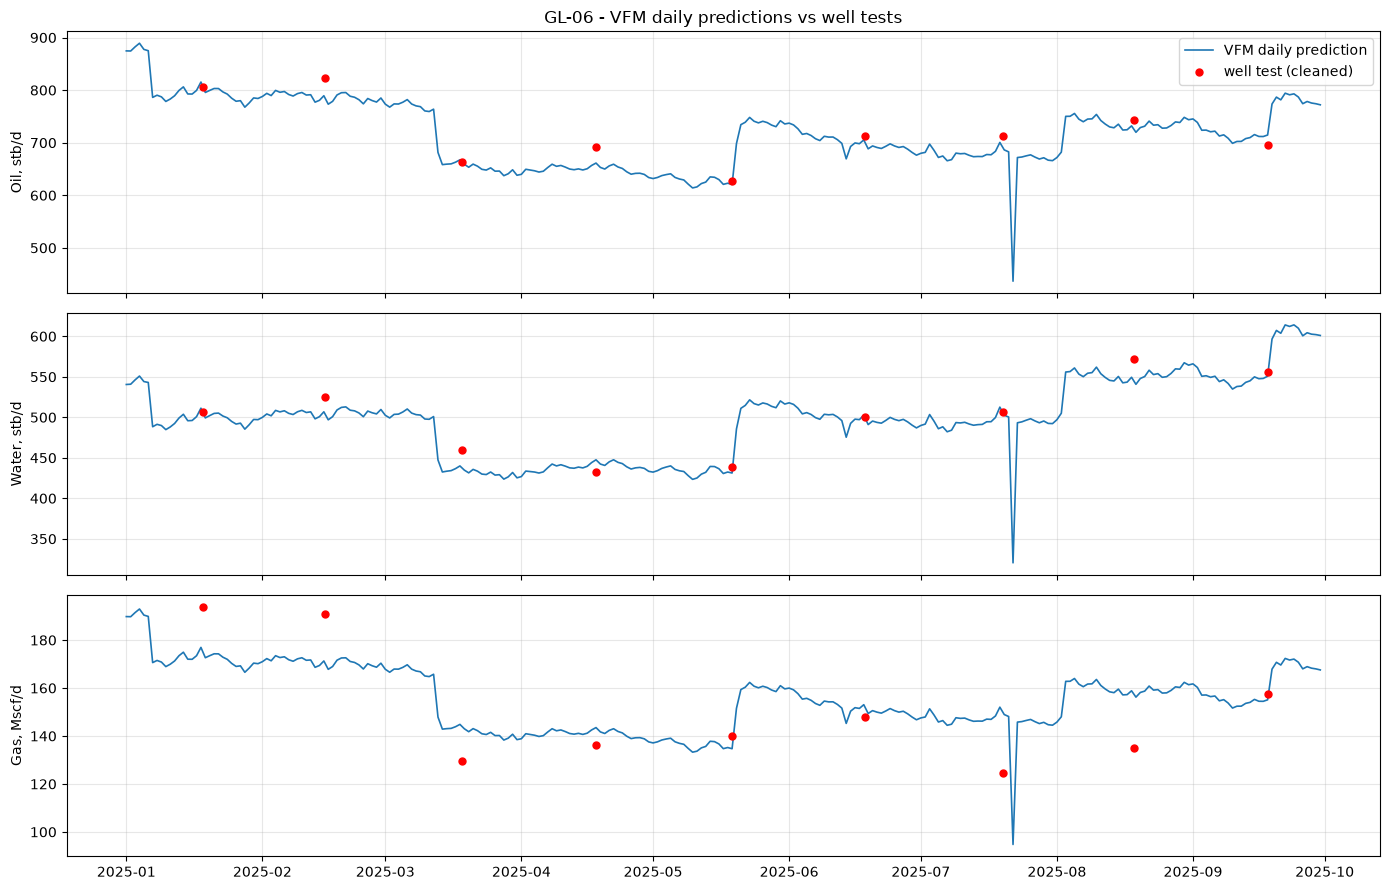

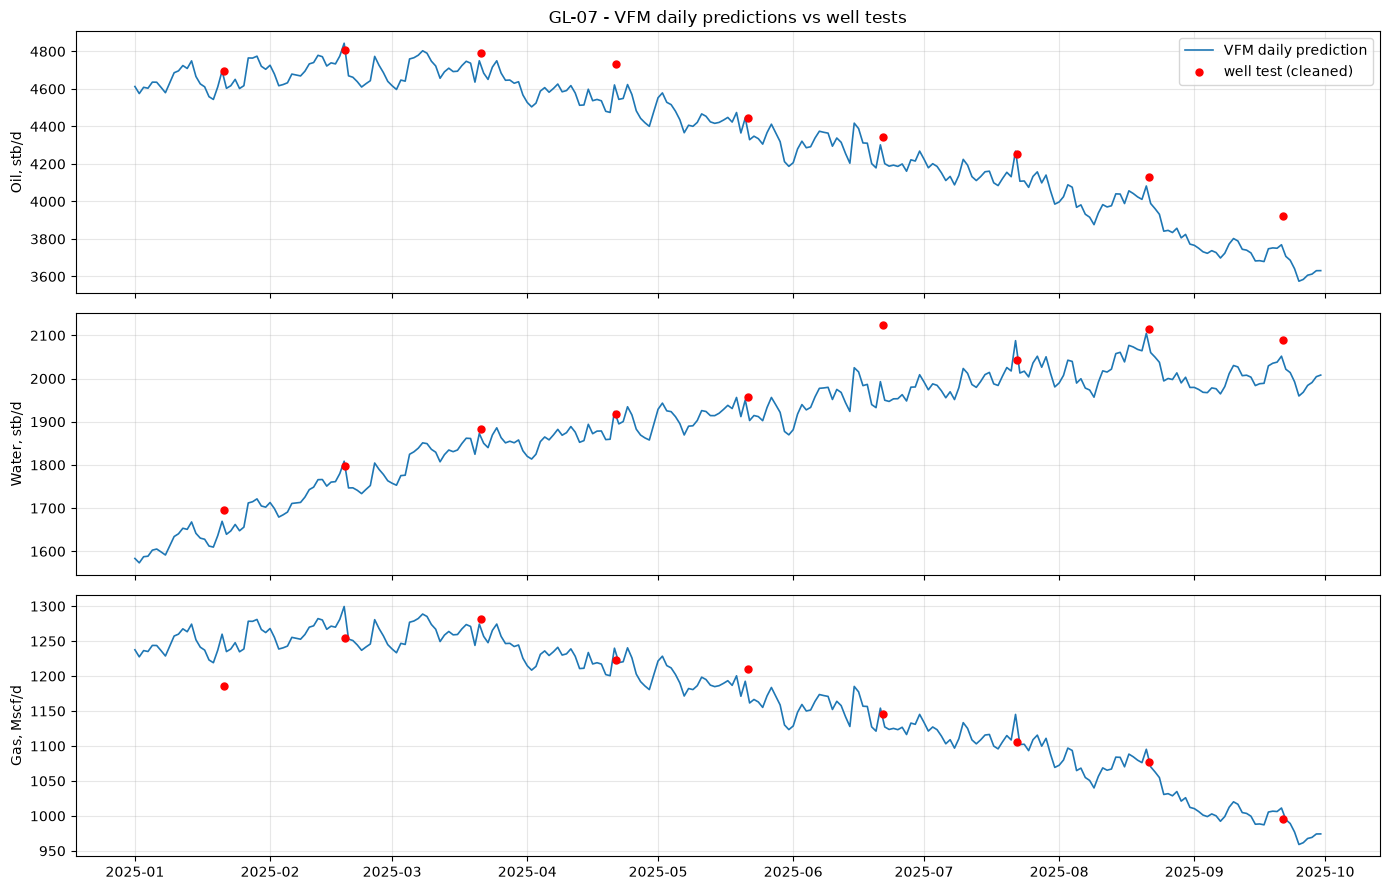

In [14]:
for w, g in P.groupby('well_name'):
    fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True); v = V[V.well_name == w]; tm = v.test_start + (v.test_end - v.test_start) / 2
    for a, col, mc, lab in zip(ax, ['oil_rate_stbd','water_rate_stbd','gas_rate_mscfd'], ['oil','water','gas'], ['Oil, stb/d','Water, stb/d','Gas, Mscf/d']):
        a.plot(g.date, g[col], lw=1.2, label='VFM daily prediction'); a.scatter(tm, v[mc + '_meas'], color='r', s=25, zorder=5, label='well test (cleaned)')
        a.set_ylabel(lab); a.grid(alpha=.3)
    ax[0].legend(); ax[0].set_title(f'{w} - VFM daily predictions vs well tests'); fig.tight_layout(); fig.savefig(OUT_DIR + f'vfm_plots/{w}_vfm.png', dpi=80)
    if w in ('GL-06', 'GL-07'): plt.show()
    plt.close(fig)

## Write the Phase 1 deliverable

In [15]:
pred = P[['date','well_name','oil_rate_stbd','water_rate_stbd','gas_rate_mscfd']].copy()
pred[['oil_rate_stbd','water_rate_stbd','gas_rate_mscfd']] = pred[['oil_rate_stbd','water_rate_stbd','gas_rate_mscfd']].round(2)
pred['date'] = pred.date.dt.strftime('%Y-%m-%d')
pred.to_csv(OUT_DIR + 'Phase1_VFM_predictions.csv', index=False)
print(len(pred), 'rows |', pred.well_name.nunique(), 'wells |', pred.date.min(), '->', pred.date.max())
pred.head()

2730 rows | 10 wells | 2025-01-01 -> 2025-09-30


,date,well_name,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
0,2025-01-01,GL-01,1168.08,769.78,324.49
1,2025-01-02,GL-01,1170.21,772.21,325.08
2,2025-01-03,GL-01,1197.48,791.26,332.66
3,2025-01-04,GL-01,1189.79,787.21,330.52
4,2025-01-05,GL-01,1174.92,778.41,326.39


## Save the trained model (`models/vfm_model.pkl`)
A plain-Python dictionary (no pandas objects inside), so it loads with any pandas / numpy version. The app predicts with it on new sensor data without needing the training files.

In [16]:
import sys, pickle
sys.path.insert(0, '..')
from wellintel.vfm import new_model_dict
to_f = lambda p: {k: (bool(v) if isinstance(v, (bool, np.bool_)) else [float(x) for x in v] if isinstance(v, (list, tuple, np.ndarray)) else float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in p.items()}
model = new_model_dict({w: to_f(p) for w, p in params.items()}, wkind, gkind, WATER_MODEL, pvt, cp, wt, prs_daily, diag, LT)
model['training_daily_oil'] = {w: {str(d.date()): float(v) for d, v in zip(g.date, g.oil_rate_stbd)} for w, g in P.groupby('well_name')}
model['training_end'] = str(c.timestamp.max())
for w in model['wells']:
    ev = ch[ch.well_name == w]
    model['wells'][w]['last_choke_pct'] = float(ev.choke_opening_pct.iloc[-1]) if len(ev) else 50.0
model['validation'] = {
    'insample_mape': {s: float(V[s + '_err_pct'].abs().mean()) for s in ['oil', 'water', 'gas']},
    'loo_mape': {s: float(LT[f'LOO_{s}_MAPE'].mean()) for s in ['oil', 'water', 'gas']},
    # out-of-time: train before a cut-off, score the later well tests (Validation_walk_forward.ipynb)
    'walk_forward_mape': {'oil': 2.06, 'water': 6.07, 'gas': 5.91, 'cutoffs': ['2025-05-01', '2025-06-01', '2025-07-01', '2025-08-01']}}
os.makedirs('../models', exist_ok=True)
with open('../models/vfm_model.pkl', 'wb') as f:
    pickle.dump(model, f, protocol=4)
print('saved ../models/vfm_model.pkl |', len(model['wells']), 'wells | trained on', model['training']['n_tests'], 'well tests')
pd.DataFrame({w: {k: p[k] for k in ['J_o', 'D_offset', 'eta_degF_per_psi', 'GOR_mscf_stb']} for w, p in model['wells'].items()}).T.round(5)

saved ../models/vfm_model.pkl | 10 wells | trained on 85 well tests


,J_o,D_offset,eta_degF_per_psi,GOR_mscf_stb
GL-01,4.28571,0.00000,0.00344,0.2778
GL-02,3.69300,0.00000,0.00312,0.3014
GL-03,1.08142,0.00000,0.00320,0.2220
GL-04,0.86836,0.00000,0.00340,0.2375
GL-05,0.76340,0.00000,0.00334,0.3257
GL-06,5.11980,69.36087,0.00508,0.2170
GL-07,19.65234,0.00000,0.00336,0.2683
GL-08,2.24287,0.00000,0.00306,0.3362
GL-09,2.48412,0.00000,0.00318,0.1600
GL-10,8.17801,0.00000,0.00324,0.2300
